# Lorenz event stopping under two batching models

This experiment compares terminal events in independently stepped trajectories
with a shared-step alternative for the broken-butterfly Lorenz system. A shared
Diffrax solve cannot terminate one lane while continuing the others, so the
alternative records threshold crossings in an absorbing state and integrates
the batch to the final time.


## Experiment implementation

Both implementations integrate the same initial conditions and return one label
per trajectory. The independent solve owns one event and controller per lane.
Shared absorption uses one controller and lane-local state instead of attaching
a scalar event to the batch.


In [1]:
import json
import platform
import statistics
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Literal, NamedTuple, cast

import diffrax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from jaxtyping import Array

BatchMode = Literal["independent_event", "shared_absorbing"]

SIGMA = 0.12
R = 0.0
B = -0.6
T0 = 0.0
T1 = 1000.0
STEADY_START = 900.0
N_SAVE = 100
DT0 = 0.04
RTOL = 1e-8
ATOL = 1e-6
ESCAPE_LIMIT = 200.0
MAX_STEPS = 20_000
SEED = 42


class LorenzParams(NamedTuple):
    """Parameters for the broken-butterfly Lorenz system."""

    sigma: float
    r: float
    b: float


PARAMS = LorenzParams(SIGMA, R, B)


@dataclass(frozen=True)
class SolveTiming:
    """Timing and step statistics for one batching implementation."""

    device: str
    batch_mode: str
    n_trajectories: int
    cold_seconds: float
    warm_seconds: list[float]
    warm_median_seconds: float
    warm_min_seconds: float
    cold_to_warm_ratio: float
    repeats: int
    median_steps: float
    max_steps: int
    median_accepted_steps: float
    median_rejected_steps: float
    max_rejected_steps: int


@dataclass(frozen=True)
class LabelAgreement:
    """Label comparison between independent events and shared masking."""

    n_trajectories: int
    agreement: float
    mismatches: int
    independent_fractions: dict[str, float]
    shared_fractions: dict[str, float]
    independent_counts: dict[str, int]
    shared_counts: dict[str, int]
    confusion_matrix: dict[str, dict[str, int]]


def lorenz_rhs(t: Any, y: Array, args: LorenzParams) -> Array:
    """Evaluate one Lorenz trajectory."""
    del t
    x, y_coordinate, z = y
    return jnp.stack((
        args.sigma * (y_coordinate - x),
        args.r * x - x * z - y_coordinate,
        x * y_coordinate - args.b * z,
    ))


def escape_measure(y: Array) -> Array:
    """Match the existing Lorenz event's ``abs(max(y))`` measure."""
    return jnp.abs(jnp.max(y, axis=-1))


def stop_condition(t: Any, y: Array, args: LorenzParams, **kwargs: Any) -> Array:
    """Return a positive scalar while one trajectory remains bounded."""
    del t, args, kwargs
    return ESCAPE_LIMIT - escape_measure(y)


def classify_tail(trajectory_tail: Array, escaped: Array) -> Array:
    """Return 0/1 for the two butterflies and 2 for an escaped trajectory."""
    x_mean = jnp.mean(jnp.where(jnp.isfinite(trajectory_tail[:, 0]), trajectory_tail[:, 0], 0))
    bounded_label = jnp.where(x_mean > 0, 0, 1)
    return jnp.where(escaped, 2, bounded_label)

In [2]:
def make_solve(batch_mode: BatchMode, device: Any) -> Any:
    """Build one jitted batching implementation."""
    save_ts = jnp.linspace(STEADY_START, T1, N_SAVE, dtype=jnp.float32, device=device)
    solver = diffrax.Tsit5()
    controller = diffrax.PIDController(rtol=RTOL, atol=ATOL)
    single_term = diffrax.ODETerm(lorenz_rhs)
    event = diffrax.Event(cond_fn=stop_condition)

    def solve_one(y0: Array) -> tuple[Array, Array]:
        solution = diffrax.diffeqsolve(
            single_term,
            solver,
            t0=T0,
            t1=T1,
            dt0=DT0,
            y0=y0,
            args=PARAMS,
            saveat=diffrax.SaveAt(ts=save_ts),
            stepsize_controller=controller,
            event=event,
            max_steps=MAX_STEPS,
        )
        trajectory_tail = cast(Array, solution.ys)
        escaped = jnp.any(jnp.isinf(trajectory_tail))
        label = classify_tail(trajectory_tail, escaped)
        stats = jnp.stack((
            solution.stats["num_steps"],
            solution.stats["num_accepted_steps"],
            solution.stats["num_rejected_steps"],
        ))
        return label, stats

    def solve_independent(y0: Array) -> tuple[Array, Array]:
        return jax.vmap(solve_one)(y0)

    def shared_rhs(t: Any, state: Array, args: LorenzParams) -> Array:
        y = state[:, :3]
        escape_marker = state[:, 3]
        derivatives = jax.vmap(lorenz_rhs, in_axes=(None, 0, None))(t, y, args)
        excess = jnp.maximum(escape_measure(y) - ESCAPE_LIMIT, 0)
        physical_derivatives = jnp.exp(-escape_marker)[:, None] * derivatives
        marker_derivative = excess
        return jnp.concatenate((physical_derivatives, marker_derivative[:, None]), axis=1)

    shared_term = diffrax.ODETerm(shared_rhs)

    def solve_shared(y0: Array) -> tuple[Array, Array]:
        initial_state = jnp.concatenate((y0, jnp.zeros((len(y0), 1), dtype=y0.dtype)), axis=1)
        solution = diffrax.diffeqsolve(
            shared_term,
            solver,
            t0=T0,
            t1=T1,
            dt0=DT0,
            y0=initial_state,
            args=PARAMS,
            saveat=diffrax.SaveAt(ts=save_ts),
            stepsize_controller=controller,
            max_steps=MAX_STEPS,
        )
        state_tails = jnp.swapaxes(cast(Array, solution.ys), 0, 1)
        trajectory_tails = state_tails[:, :, :3]
        escaped = state_tails[:, -1, 3] > 0
        labels = jax.vmap(classify_tail)(trajectory_tails, escaped)
        stats = jnp.stack((
            solution.stats["num_steps"],
            solution.stats["num_accepted_steps"],
            solution.stats["num_rejected_steps"],
        ))
        return labels, stats

    solve = solve_independent if batch_mode == "independent_event" else solve_shared
    return jax.jit(solve)


def generate_initial_conditions(n_trajectories: int, device: Any) -> Array:
    """Generate the deterministic initial-condition sample used by the prototype."""
    key = jax.random.PRNGKey(SEED)
    minimum = jnp.array([-10.0, -20.0, 0.0], dtype=jnp.float32)
    maximum = jnp.array([10.0, 20.0, 0.0], dtype=jnp.float32)
    initial_conditions = jax.random.uniform(
        key,
        shape=(n_trajectories, 3),
        minval=minimum,
        maxval=maximum,
    )
    return jax.device_put(initial_conditions, device)


def benchmark(
    y0: Array,
    batch_mode: BatchMode,
    device_name: str,
    device: Any,
    repeats: int,
) -> tuple[SolveTiming, np.ndarray]:
    """Measure one cold call and repeated calls at the same compiled shape."""
    jax.clear_caches()
    solve = make_solve(batch_mode, device)

    start = time.perf_counter()
    labels, stats_jax = solve(y0)
    jax.block_until_ready((labels, stats_jax))
    cold_seconds = time.perf_counter() - start

    warm_seconds: list[float] = []
    for _ in range(repeats):
        start = time.perf_counter()
        labels, stats_jax = solve(y0)
        jax.block_until_ready((labels, stats_jax))
        warm_seconds.append(time.perf_counter() - start)

    labels_numpy = np.asarray(labels)
    stats = np.asarray(stats_jax)
    if batch_mode == "independent_event":
        median_steps = float(np.median(stats[:, 0]))
        max_step_count = int(np.max(stats[:, 0]))
        median_accepted = float(np.median(stats[:, 1]))
        median_rejected = float(np.median(stats[:, 2]))
        max_rejected = int(np.max(stats[:, 2]))
    else:
        median_steps = float(stats[0])
        max_step_count = int(stats[0])
        median_accepted = float(stats[1])
        median_rejected = float(stats[2])
        max_rejected = int(stats[2])

    warm_median = statistics.median(warm_seconds)
    timing = SolveTiming(
        device=device_name,
        batch_mode=batch_mode,
        n_trajectories=len(y0),
        cold_seconds=cold_seconds,
        warm_seconds=warm_seconds,
        warm_median_seconds=warm_median,
        warm_min_seconds=min(warm_seconds),
        cold_to_warm_ratio=cold_seconds / warm_median,
        repeats=repeats,
        median_steps=median_steps,
        max_steps=max_step_count,
        median_accepted_steps=median_accepted,
        median_rejected_steps=median_rejected,
        max_rejected_steps=max_rejected,
    )
    return timing, labels_numpy

In [3]:
def label_summary(labels: np.ndarray) -> tuple[dict[str, int], dict[str, float]]:
    """Return counts and fractions in the stable label order."""
    names = ("butterfly1", "butterfly2", "unbounded")
    counts = {name: int(np.count_nonzero(labels == index)) for index, name in enumerate(names)}
    fractions = {name: count / len(labels) for name, count in counts.items()}
    return counts, fractions


def compare_labels(independent: np.ndarray, shared: np.ndarray) -> LabelAgreement:
    """Compare the two implementations trajectory by trajectory."""
    names = ("butterfly1", "butterfly2", "unbounded")
    independent_counts, independent_fractions = label_summary(independent)
    shared_counts, shared_fractions = label_summary(shared)
    mismatches = int(np.count_nonzero(independent != shared))
    confusion_matrix = {
        independent_name: {
            shared_name: int(
                np.count_nonzero((independent == independent_index) & (shared == shared_index))
            )
            for shared_index, shared_name in enumerate(names)
        }
        for independent_index, independent_name in enumerate(names)
    }
    return LabelAgreement(
        n_trajectories=len(independent),
        agreement=float(np.mean(independent == shared)),
        mismatches=mismatches,
        independent_fractions=independent_fractions,
        shared_fractions=shared_fractions,
        independent_counts=independent_counts,
        shared_counts=shared_counts,
        confusion_matrix=confusion_matrix,
    )


def global_event_diagnostic(device: Any) -> dict[str, Any]:
    """Show the batch-wide termination caused by a scalar shared event."""
    y0 = jax.device_put(
        jnp.array(
            [[0.8, -3.0, 0.0], [-0.8, 3.0, 0.0], [10.0, 50.0, 0.0]],
            dtype=jnp.float32,
        ),
        device,
    )
    save_ts = jnp.linspace(T0, T1, 1000, dtype=jnp.float32, device=device)

    def shared_rhs(t: Any, y: Array, args: LorenzParams) -> Array:
        return jax.vmap(lorenz_rhs, in_axes=(None, 0, None))(t, y, args)

    def batch_stop_condition(
        t: Any,
        y: Array,
        args: LorenzParams,
        **kwargs: Any,
    ) -> Array:
        del t, args, kwargs
        return ESCAPE_LIMIT - jnp.abs(jnp.max(y))

    solution = diffrax.diffeqsolve(
        diffrax.ODETerm(shared_rhs),
        diffrax.Tsit5(),
        t0=T0,
        t1=T1,
        dt0=DT0,
        y0=y0,
        args=PARAMS,
        saveat=diffrax.SaveAt(ts=save_ts),
        stepsize_controller=diffrax.PIDController(rtol=RTOL, atol=ATOL),
        event=diffrax.Event(cond_fn=batch_stop_condition),
        max_steps=MAX_STEPS,
    )
    trajectories = cast(Array, solution.ys)
    jax.block_until_ready(trajectories)
    finite_by_time = jnp.all(jnp.isfinite(trajectories), axis=(1, 2))
    finite_indices = jnp.where(finite_by_time, jnp.arange(len(save_ts)), -1)
    return {
        "event_occurred": bool(jnp.any(jnp.isinf(trajectories))),
        "all_trajectories_have_inf_padding": bool(
            jnp.all(jnp.any(jnp.isinf(trajectories), axis=(0, 2)))
        ),
        "last_jointly_finite_save_index": int(jnp.max(finite_indices)),
        "num_steps": int(solution.stats["num_steps"]),
    }


def resolve_device(name: str) -> Any:
    """Resolve one JAX device or fail with a concise message."""
    backend = "gpu" if name == "gpu" else "cpu"
    devices = jax.devices(backend)
    if not devices:
        raise RuntimeError(f"No JAX {backend} device is available.")
    return devices[0]

In [4]:
def run(
    device_name: str,
    n_trajectories: int,
    repeats: int,
) -> dict[str, Any]:
    """Run the batching comparison and scalar-event diagnostic."""
    device = resolve_device(device_name)
    y0 = generate_initial_conditions(n_trajectories, device)
    timings: list[SolveTiming] = []
    labels_by_mode: dict[BatchMode, np.ndarray] = {}

    for batch_mode in ("independent_event", "shared_absorbing"):
        print(f"{device_name} {batch_mode} N={n_trajectories:,}", flush=True)
        timing, labels = benchmark(y0, batch_mode, device_name, device, repeats)
        timings.append(timing)
        labels_by_mode[batch_mode] = labels

    agreement = compare_labels(
        labels_by_mode["independent_event"],
        labels_by_mode["shared_absorbing"],
    )
    diagnostic = global_event_diagnostic(device)
    return {
        "configuration": {
            "device": device_name,
            "n_trajectories": n_trajectories,
            "repeats": repeats,
            "time_span": [T0, T1],
            "steady_start": STEADY_START,
            "n_save": N_SAVE,
            "dtype": "float32",
            "rtol": RTOL,
            "atol": ATOL,
            "dt0": DT0,
            "escape_limit": ESCAPE_LIMIT,
            "timed_operation": (
                "Integrate one batch, save the final steady-state window, and return "
                "one basin label per initial condition"
            ),
        },
        "environment": {
            "platform": platform.platform(),
            "python": platform.python_version(),
            "jax": jax.__version__,
            "diffrax": diffrax.__version__,
            "device": str(device),
            "jax_x64_enabled": jax.config.x64_enabled,
        },
        "timings": [asdict(timing) for timing in timings],
        "label_agreement": asdict(agreement),
        "global_event_diagnostic": diagnostic,
    }

## Execute or reuse the recorded run

Set `RUN_FULL_EXPERIMENT` to `True` to repeat the CPU measurement. The GPU path
uses the same implementation but has no committed result yet.


In [5]:
RUN_FULL_EXPERIMENT = False

repo_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file()
)
artifact_path = (
    repo_root
    / "packages/pybasin/docs/evaluation/design-studies/artifacts/lorenz_batching_event_cpu_results.json"
)

if RUN_FULL_EXPERIMENT:
    results = run("cpu", n_trajectories=10_000, repeats=3)
    artifact_path.write_text(json.dumps(results, indent=2) + "\n")
else:
    results = json.loads(artifact_path.read_text())

print(json.dumps(results["environment"], indent=2))

{
  "platform": "Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43",
  "python": "3.12.13",
  "jax": "0.11.0",
  "diffrax": "0.7.2",
  "device": "cpu:0",
  "jax_x64_enabled": false
}


## Performance and label agreement

Timing includes integration, the final steady-state save window, and one output
label per initial condition. Initial-condition generation and device transfer
are excluded.


In [6]:
timing = pd.DataFrame(results["timings"])
display(
    timing[
        [
            "batch_mode",
            "cold_seconds",
            "warm_median_seconds",
            "median_steps",
            "median_rejected_steps",
            "max_rejected_steps",
        ]
    ]
)

agreement = results["label_agreement"]
counts = pd.DataFrame({
    "independent_event": agreement["independent_counts"],
    "shared_absorbing": agreement["shared_counts"],
})
display(counts)
display(pd.DataFrame(agreement["confusion_matrix"]))

,batch_mode,cold_seconds,warm_median_seconds,median_steps,median_rejected_steps,max_rejected_steps
0,independent_event,8.366803,7.549302,255.0,20.0,940
1,shared_absorbing,5.113674,4.743188,10564.0,1783.0,1783


,independent_event,shared_absorbing
butterfly1,907,907
butterfly2,898,900
unbounded,8195,8193


,butterfly1,butterfly2,unbounded
butterfly1,905,0,2
butterfly2,0,896,4
unbounded,2,2,8189


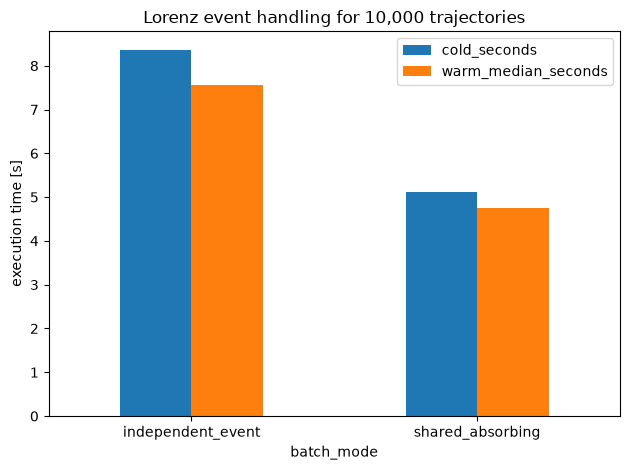

Label agreement: 99.900%
Mismatched trajectories: 10
Scalar shared event pads every trajectory with infinity: True


In [7]:
ax = timing.plot.bar(
    x="batch_mode",
    y=["cold_seconds", "warm_median_seconds"],
    ylabel="execution time [s]",
    title="Lorenz event handling for 10,000 trajectories",
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

diagnostic = results["global_event_diagnostic"]
print(f"Label agreement: {agreement['agreement']:.3%}")
print(f"Mismatched trajectories: {agreement['mismatches']}")
print(
    "Scalar shared event pads every trajectory with infinity: "
    f"{diagnostic['all_trajectories_have_inf_padding']}"
)

Independent events remain the correctness path when terminal time, terminal
state, or event reason matters. Shared absorption is a distinct throughput
policy. Its labels need validation for each target system, and a scalar Diffrax
event must never be attached to a mixed shared batch.
